# Sentiment Classifier: TF-IDF + Multi-Layer Neural Network (PyTorch)

**Task:** Build an NLP text-classification pipeline (sentiment analysis) with a deep neural network.

**Pipeline**
1. Tokenize and vectorize text with **TF-IDF** (unigrams + bigrams)
2. Build a multi-layer network with **Dropout**, **Batch Normalization** and **early stopping**
3. Train and validate, plotting **loss and accuracy convergence curves**
4. Evaluate on a held-out test set and run **inference on unseen sentences** with classification confidences


In [1]:
import os, random, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0+cu132 | device: cpu


## 1. Data

If a file named `reviews.csv` (columns `text`, `label` with 0 = negative, 1 = positive) exists next to this notebook, it is used, so you can drop in IMDB, Amazon reviews, an SMS-spam set, etc.

Otherwise a synthetic review corpus is generated. It deliberately includes **negation** ("not good"), **mixed sentiment** where the final clause decides the label ("great acting but a terrible ending") and **5% label noise**, so the task is not trivially separable.

In [2]:
def make_synthetic(n=8000, noise=0.05, seed=SEED):
    rng = random.Random(seed)
    subjects = ["movie", "film", "product", "service", "hotel", "restaurant", "app", "book", "phone", "show", "game", "laptop"]
    pos = ["excellent", "fantastic", "wonderful", "amazing", "great", "brilliant", "superb", "delightful", "impressive", "outstanding", "lovely", "fun"]
    neg = ["terrible", "awful", "horrible", "disappointing", "boring", "poor", "dreadful", "mediocre", "annoying", "useless", "broken", "dull"]
    intens = ["", "really ", "very ", "absolutely ", "truly ", "quite ", "incredibly "]
    pos_t = ["I loved this {s}, it was {i}{a}.", "What a {i}{a} {s}!", "This {s} is {i}{a} and worth every penny.",
             "Highly recommend the {s}, truly {a}.", "The {s} exceeded my expectations, {i}{a} experience.",
             "Such a {i}{a} {s}, I would buy it again."]
    neg_t = ["I hated this {s}, it was {i}{a}.", "What a {i}{a} {s}...", "This {s} is {i}{a} and a waste of money.",
             "Do not recommend the {s}, truly {a}.", "The {s} failed my expectations, {i}{a} experience.",
             "Such a {i}{a} {s}, I want a refund."]
    negation_pos = ["This {s} is not {n} at all, I enjoyed it.", "I can't say the {s} was {n}, it was actually good.",
                    "Never found the {s} {n}, quite the opposite."]
    negation_neg = ["This {s} is not {p} at all, I regret it.", "I can't say the {s} was {p}, it was honestly bad.",
                    "Never found the {s} {p}, quite the opposite."]
    mixed_pos = ["At first the {s} felt {n}, but in the end it was {p}.", "Some parts were {n}, however overall the {s} is {p}.",
                 "Despite a {n} start, the {s} turned out {p}."]
    mixed_neg = ["At first the {s} seemed {p}, but in the end it was {n}.", "Some parts were {p}, however overall the {s} is {n}.",
                 "Despite a {p} start, the {s} turned out {n}."]
    rows = []
    for _ in range(n):
        label = rng.randint(0, 1)
        s = rng.choice(subjects); i = rng.choice(intens); p = rng.choice(pos); ng = rng.choice(neg)
        kind = rng.random()
        if kind < 0.55:
            t = rng.choice(pos_t if label else neg_t).format(s=s, i=i, a=rng.choice(pos if label else neg))
        elif kind < 0.78:
            t = rng.choice(negation_pos if label else negation_neg).format(s=s, n=ng, p=p)
        else:
            t = rng.choice(mixed_pos if label else mixed_neg).format(s=s, n=ng, p=p)
        if rng.random() < 0.3:
            t += " " + rng.choice(["Delivery was on time.", "I watched it on a weekend.", "My friend told me about it.", "Bought it last month."])
        if rng.random() < noise:
            label = 1 - label   # label noise
        rows.append((t, label))
    return pd.DataFrame(rows, columns=["text", "label"])

if os.path.exists("reviews.csv"):
    df = pd.read_csv("reviews.csv")[["text", "label"]].dropna()
    DATA_SOURCE = "reviews.csv"
else:
    df = make_synthetic()
    DATA_SOURCE = "synthetic reviews"
print(f"Data source: {DATA_SOURCE} | {len(df):,} samples")
print(df["label"].value_counts().rename({0: "negative", 1: "positive"}).to_string())
df.sample(5, random_state=1)

Data source: synthetic reviews | 8,000 samples
label
positive    4080
negative    3920


,text,label
4740,This phone is quite fantastic and worth every ...,1
5606,"I loved this product, it was incredibly amazing.",1
4824,"This game is not impressive at all, I regret it.",0
4205,"This product is not delightful at all, I regre...",0
3228,What a truly boring show...,0


## 2. Tokenize and vectorize (TF-IDF)

The vectorizer is **fit on the training split only**, so no information from validation or test data leaks into the features.

In [3]:
X_train_txt, X_tmp_txt, y_train, y_tmp = train_test_split(df["text"], df["label"], test_size=0.30, stratify=df["label"], random_state=SEED)
X_val_txt, X_test_txt, y_val, y_test = train_test_split(X_tmp_txt, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print(f"train={len(X_train_txt):,}  val={len(X_val_txt):,}  test={len(X_test_txt):,}")

vectorizer = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, max_features=5000, sublinear_tf=True)
Xtr = vectorizer.fit_transform(X_train_txt)
Xva = vectorizer.transform(X_val_txt)
Xte = vectorizer.transform(X_test_txt)
print("TF-IDF matrix:", Xtr.shape, "| vocabulary size:", len(vectorizer.vocabulary_))
print("Sample features:", list(vectorizer.vocabulary_)[:12])

to_t = lambda X: torch.tensor(X.toarray(), dtype=torch.float32)
Xtr_t, Xva_t, Xte_t = to_t(Xtr), to_t(Xva), to_t(Xte)
ytr_t, yva_t, yte_t = (torch.tensor(y.values, dtype=torch.long) for y in (y_train, y_val, y_test))

train_loader = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=64, shuffle=True)
val_loader = DataLoader(TensorDataset(Xva_t, yva_t), batch_size=256)

train=5,600  val=1,200  test=1,200
TF-IDF matrix: (5600, 1470) | vocabulary size: 1470
Sample features: ['at', 'first', 'the', 'phone', 'seemed', 'amazing', 'but', 'in', 'end', 'it', 'was', 'horrible']


## 3. Model: multi-layer network with Dropout and Batch Normalization

`Linear → BatchNorm → ReLU → Dropout` blocks, followed by a 2-class output layer.

In [4]:
class TextClassifier(nn.Module):
    def __init__(self, in_dim, hidden=(256, 64), n_classes=2, dropout=(0.4, 0.3)):
        super().__init__()
        layers, prev = [], in_dim
        for h, p in zip(hidden, dropout):
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(p)]
            prev = h
        layers.append(nn.Linear(prev, n_classes))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

model = TextClassifier(Xtr_t.shape[1]).to(device)
print(model)
print("Trainable parameters:", f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

TextClassifier(
  (net): Sequential(
    (0): Linear(in_features=1470, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=256, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=64, out_features=2, bias=True)
  )
)
Trainable parameters: 393,794


## 4. Training with early stopping

Early stopping monitors **validation loss**, stops after `patience` epochs without improvement, and restores the best weights.

In [5]:
class EarlyStopping:
    def __init__(self, patience=5, min_delta=1e-4):
        self.patience, self.min_delta = patience, min_delta
        self.best, self.counter, self.best_state, self.stop = float("inf"), 0, None, False
    def __call__(self, val_loss, model):
        if val_loss < self.best - self.min_delta:
            self.best, self.counter = val_loss, 0
            self.best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.stop = True

def run_epoch(loader, train):
    model.train(train)
    total_loss = correct = n = 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss = criterion(out, yb)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item() * len(xb)
            correct += (out.argmax(1) == yb).sum().item()
            n += len(xb)
    return total_loss / n, correct / n

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
stopper = EarlyStopping(patience=5)
MAX_EPOCHS = 50
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

for epoch in range(1, MAX_EPOCHS + 1):
    tl, ta = run_epoch(train_loader, True)
    vl, va = run_epoch(val_loader, False)
    for k, v in zip(history, (tl, vl, ta, va)):
        history[k].append(v)
    print(f"Epoch {epoch:02d} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}")
    stopper(vl, model)
    if stopper.stop:
        print(f"Early stopping at epoch {epoch}; best val loss {stopper.best:.4f}")
        break

model.load_state_dict(stopper.best_state)
best_epoch = int(np.argmin(history["val_loss"])) + 1
print("Restored best weights from epoch", best_epoch)

Epoch 01 | train loss 0.3532 acc 0.8707 | val loss 0.2155 acc 0.9542


Epoch 02 | train loss 0.2089 acc 0.9437 | val loss 0.2102 acc 0.9508


Epoch 03 | train loss 0.1814 acc 0.9463 | val loss 0.2385 acc 0.9500


Epoch 04 | train loss 0.1557 acc 0.9468 | val loss 0.2462 acc 0.9500


Epoch 05 | train loss 0.1436 acc 0.9493 | val loss 0.2644 acc 0.9433


Epoch 06 | train loss 0.1319 acc 0.9543 | val loss 0.2747 acc 0.9408


Epoch 07 | train loss 0.1174 acc 0.9593 | val loss 0.2993 acc 0.9375
Early stopping at epoch 7; best val loss 0.2102
Restored best weights from epoch 2


## 5. Loss and accuracy convergence curves

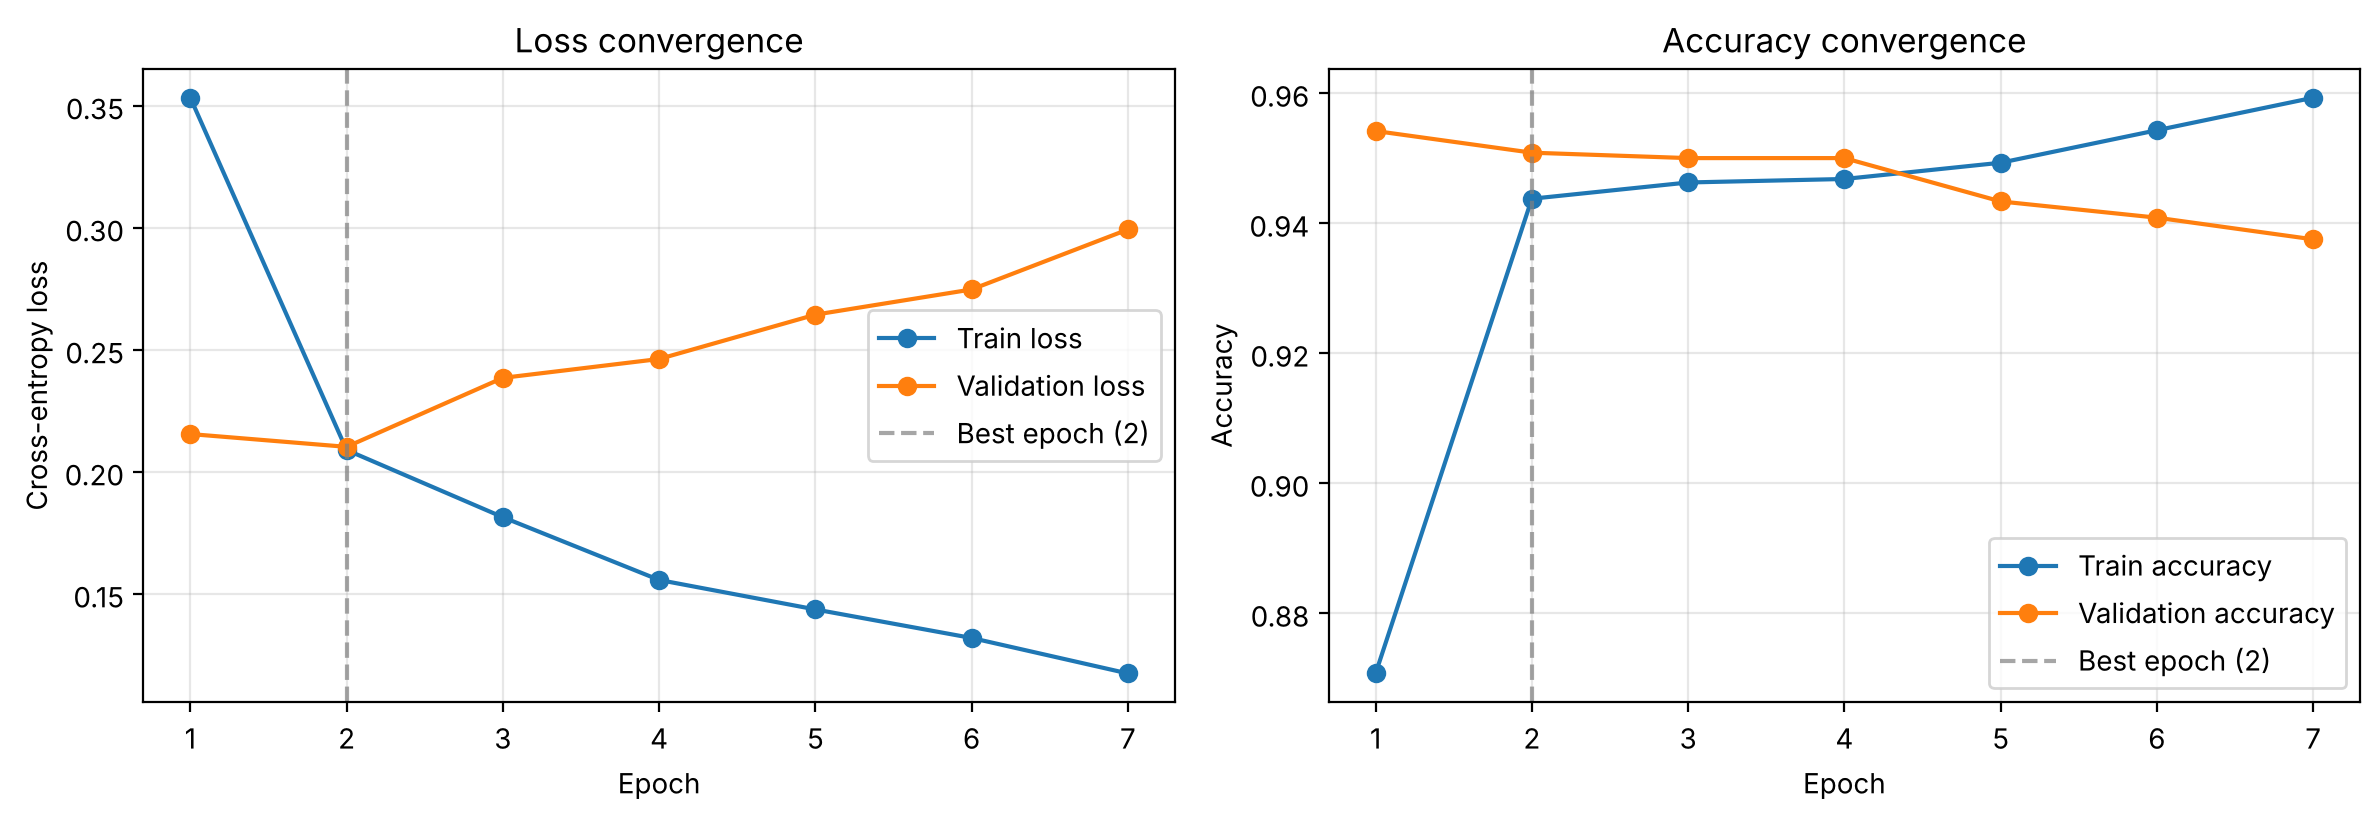

In [6]:
epochs = range(1, len(history["train_loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))

ax[0].plot(epochs, history["train_loss"], marker="o", label="Train loss")
ax[0].plot(epochs, history["val_loss"], marker="o", label="Validation loss")
ax[0].axvline(best_epoch, color="gray", linestyle="--", alpha=.7, label=f"Best epoch ({best_epoch})")
ax[0].set(title="Loss convergence", xlabel="Epoch", ylabel="Cross-entropy loss"); ax[0].legend(); ax[0].grid(alpha=.3)

ax[1].plot(epochs, history["train_acc"], marker="o", label="Train accuracy")
ax[1].plot(epochs, history["val_acc"], marker="o", label="Validation accuracy")
ax[1].axvline(best_epoch, color="gray", linestyle="--", alpha=.7, label=f"Best epoch ({best_epoch})")
ax[1].set(title="Accuracy convergence", xlabel="Epoch", ylabel="Accuracy"); ax[1].legend(); ax[1].grid(alpha=.3)

plt.tight_layout(); plt.savefig("training_curves.png", dpi=150); plt.show()

## 6. Evaluation on the unseen test set

Test accuracy: 0.9392

              precision    recall  f1-score   support

    negative     0.9270    0.9507    0.9387       588
    positive     0.9514    0.9281    0.9396       612

    accuracy                         0.9392      1200
   macro avg     0.9392    0.9394    0.9392      1200
weighted avg     0.9395    0.9392    0.9392      1200



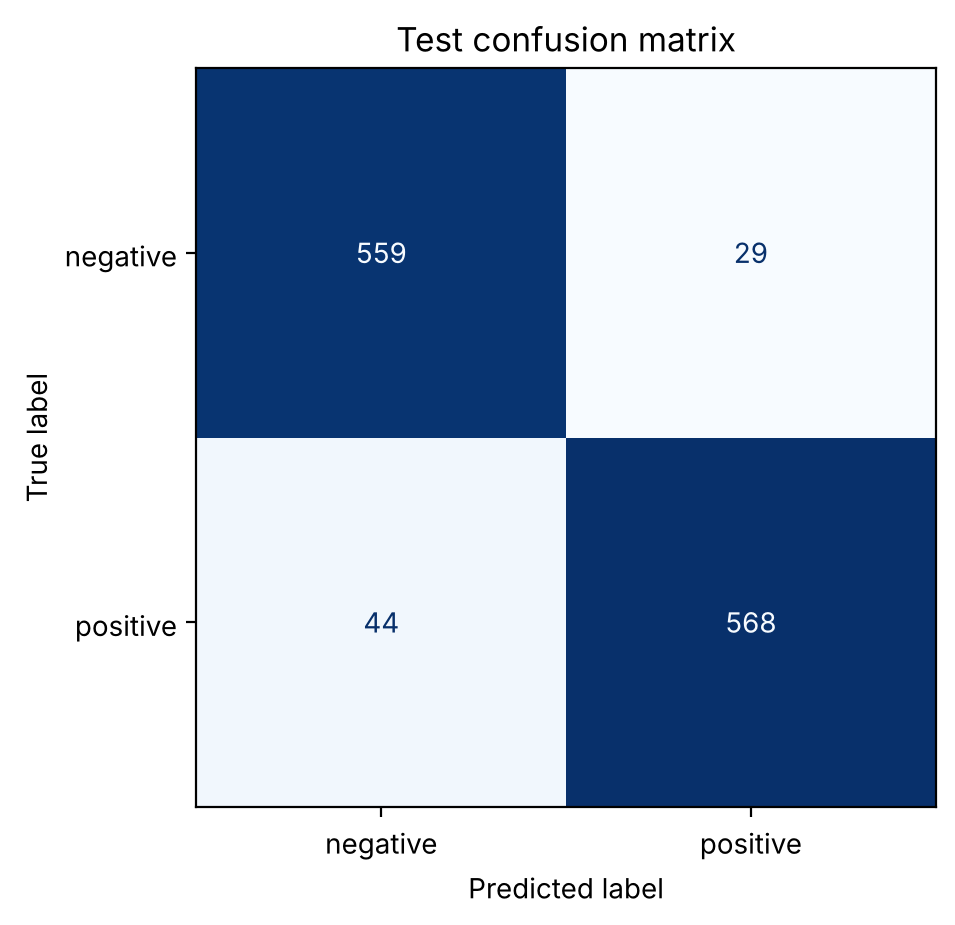

In [7]:
model.eval()
with torch.no_grad():
    test_logits = model(Xte_t.to(device)).cpu()
test_pred = test_logits.argmax(1).numpy()
test_acc = (test_pred == yte_t.numpy()).mean()
print(f"Test accuracy: {test_acc:.4f}\n")
print(classification_report(yte_t.numpy(), test_pred, target_names=["negative", "positive"], digits=4))

cm = confusion_matrix(yte_t.numpy(), test_pred)
ConfusionMatrixDisplay(cm, display_labels=["negative", "positive"]).plot(cmap="Blues", colorbar=False)
plt.title("Test confusion matrix"); plt.show()

## 7. Inference on unseen sample inputs, with classification confidences

Softmax probabilities give the confidence for each class. These sentences are written by hand and are not in the training data.

In [8]:
def predict(texts):
    X = to_t(vectorizer.transform(texts)).to(device)
    model.eval()
    with torch.no_grad():
        probs = torch.softmax(model(X), dim=1).cpu().numpy()
    return probs

samples = [
    "I absolutely loved this phone, the battery life is fantastic!",
    "Terrible service, the hotel was dirty and the staff were awful.",
    "This movie was not bad at all, I really enjoyed it.",
    "The app is boring and completely useless, I want a refund.",
    "Some parts were dull, however overall the book is brilliant.",
    "At first the game seemed great, but in the end it was disappointing.",
    "Delivery was on time.",
    "What a wonderful restaurant, highly recommend it!",
]
probs = predict(samples)
labels = ["negative", "positive"]
result = pd.DataFrame({
    "text": samples,
    "prediction": [labels[i] for i in probs.argmax(1)],
    "confidence": probs.max(1).round(4),
    "P(negative)": probs[:, 0].round(4),
    "P(positive)": probs[:, 1].round(4),
})
pd.set_option("display.max_colwidth", 80, "display.width", 200)
print(result.to_string(index=False))

                                                                text prediction  confidence  P(negative)  P(positive)
       I absolutely loved this phone, the battery life is fantastic!   positive      0.9882       0.0118       0.9882
     Terrible service, the hotel was dirty and the staff were awful.   positive      0.5816       0.4184       0.5816
                 This movie was not bad at all, I really enjoyed it.   positive      0.8925       0.1075       0.8925
          The app is boring and completely useless, I want a refund.   negative      0.9881       0.9881       0.0119
        Some parts were dull, however overall the book is brilliant.   positive      0.9334       0.0666       0.9334
At first the game seemed great, but in the end it was disappointing.   negative      0.8972       0.8972       0.1028
                                               Delivery was on time.   negative      0.5404       0.5404       0.4596
                   What a wonderful restaurant, highly r

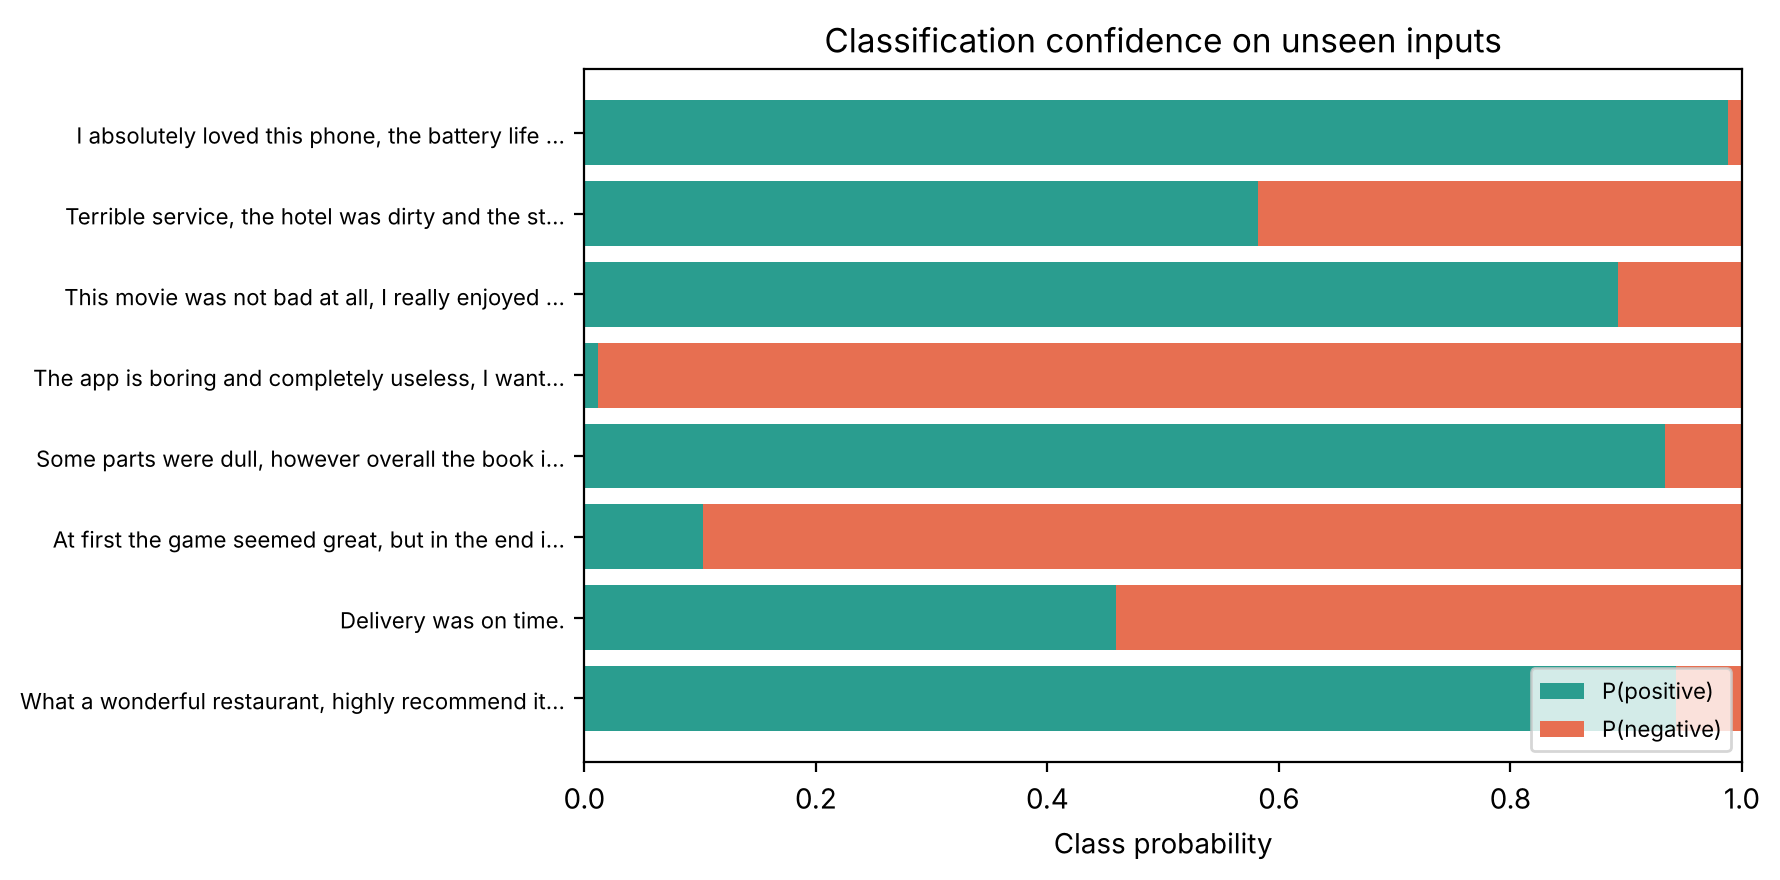

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(len(samples))
ax.barh(y, probs[:, 1], color="#2a9d8f", label="P(positive)")
ax.barh(y, probs[:, 0], left=probs[:, 1], color="#e76f51", label="P(negative)")
ax.set_yticks(y); ax.set_yticklabels([s[:48] + ("…" if len(s) > 48 else "") for s in samples], fontsize=8)
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel("Class probability")
ax.set_title("Classification confidence on unseen inputs"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

## Summary

| Requirement | Implementation |
|---|---|
| Tokenize and vectorize | `TfidfVectorizer` with unigrams + bigrams, 5,000 features, fit on train only |
| Multi-layer network | 3 `Linear` layers (input → 256 → 64 → 2) |
| Dropout, BatchNorm, early stopping | `Dropout(0.4/0.3)`, `BatchNorm1d`, custom `EarlyStopping` on validation loss with best-weight restore |
| Train and validate with curves | Per-epoch train/val loss and accuracy plotted |
| Test on unseen inputs | Held-out test report plus hand-written sentences with softmax confidences |

**Notes:** Results above come from the synthetic corpus, which has 5% label noise, so the ceiling is roughly 95%. To use real data, put a `reviews.csv` (`text`, `label`) beside the notebook and re-run all cells. To use Hugging Face embeddings instead of TF-IDF, replace the vectorization cell and set the model's input dimension to the embedding size.